# P07 – Legendary or Not? Pokémon Classifier
**Name:** ARSHIYA QUAZI
**Roll No.:** H35
**Enrollment No.:** 24004501210340
**Division:** E


In [6]:
# 1
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import sklearn

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    confusion_matrix, ConfusionMatrixDisplay, classification_report,
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve
)

In [11]:
# 2
df_original = pd.read_csv("Pokemon.csv")
print("Dataset shape (rows, columns):", df_original.shape)
display(df_original.head())

Dataset shape (rows, columns): (800, 13)


,#,Name,Type 1,Type 2,Total,HP,Attack,Defense,Sp. Atk,Sp. Def,Speed,Generation,Legendary
0,1,Bulbasaur,Grass,Poison,318,45,49,49,65,65,45,1,False
1,2,Ivysaur,Grass,Poison,405,60,62,63,80,80,60,1,False
2,3,Venusaur,Grass,Poison,525,80,82,83,100,100,80,1,False
3,3,VenusaurMega Venusaur,Grass,Poison,625,80,100,123,122,120,80,1,False
4,4,Charmander,Fire,NaN,309,39,52,43,60,50,65,1,False


In [12]:
# 3
print("Column information:")
df_original.info()

print("\nNumeric summary:")
display(df_original.describe(include="all").T)

print("\nMissing values:")
display(df_original.isnull().sum().to_frame("Missing values"))

print("\nExact duplicate rows:", df_original.duplicated().sum())

print("\nTarget counts:")
display(df_original["Legendary"].value_counts(dropna=False).to_frame("Count"))

print("\nTarget proportions:")
display(df_original["Legendary"].value_counts(normalize=True, dropna=False).mul(100).round(2).to_frame("Percent"))

Column information:
<class 'pandas.DataFrame'>
RangeIndex: 800 entries, 0 to 799
Data columns (total 13 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   #           800 non-null    int64
 1   Name        800 non-null    str  
 2   Type 1      800 non-null    str  
 3   Type 2      414 non-null    str  
 4   Total       800 non-null    int64
 5   HP          800 non-null    int64
 6   Attack      800 non-null    int64
 7   Defense     800 non-null    int64
 8   Sp. Atk     800 non-null    int64
 9   Sp. Def     800 non-null    int64
 10  Speed       800 non-null    int64
 11  Generation  800 non-null    int64
 12  Legendary   800 non-null    bool 
dtypes: bool(1), int64(9), str(3)
memory usage: 75.9 KB

Numeric summary:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
#,800.0,NaN,NaN,NaN,362.81375,208.343798,1.0,184.75,364.5,539.25,721.0
Name,800,800,Bulbasaur,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Type 1,800,18,Water,112,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Type 2,414,18,Flying,97,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Total,800.0,NaN,NaN,NaN,435.1025,119.96304,180.0,330.0,450.0,515.0,780.0
HP,800.0,NaN,NaN,NaN,69.25875,25.534669,1.0,50.0,65.0,80.0,255.0
Attack,800.0,NaN,NaN,NaN,79.00125,32.457366,5.0,55.0,75.0,100.0,190.0
Defense,800.0,NaN,NaN,NaN,73.8425,31.183501,5.0,50.0,70.0,90.0,230.0
Sp. Atk,800.0,NaN,NaN,NaN,72.82,32.722294,10.0,49.75,65.0,95.0,194.0
Sp. Def,800.0,NaN,NaN,NaN,71.9025,27.828916,20.0,50.0,70.0,90.0,230.0



Missing values:


,Missing values
#,0
Name,0
Type 1,0
Type 2,386
Total,0
HP,0
Attack,0
Defense,0
Sp. Atk,0
Sp. Def,0



Exact duplicate rows: 0

Target counts:


,Count
Legendary,
False,735
True,65



Target proportions:


,Percent
Legendary,
False,91.88
True,8.12


In [13]:
# 4
meanings = {
    "#": ("Pokédex identifier", "Identifier; drop"),
    "Name": ("Pokémon name", "Text; drop"),
    "Type 1": ("Primary Pokémon type", "Categorical; keep"),
    "Type 2": ("Secondary Pokémon type", "Categorical; keep; fill missing"),
    "Total": ("Sum of base stats in the source dataset", "Numeric; drop to avoid duplicating derived total"),
    "HP": ("Hit points", "Numeric; keep"),
    "Attack": ("Physical attack stat", "Numeric; keep"),
    "Defense": ("Physical defense stat", "Numeric; keep"),
    "Sp. Atk": ("Special attack stat", "Numeric; keep"),
    "Sp. Def": ("Special defense stat", "Numeric; keep"),
    "Speed": ("Speed stat", "Numeric; keep"),
    "Generation": ("Generation in which the Pokémon was introduced", "Numeric; keep"),
    "Legendary": ("Whether the Pokémon is classified as Legendary", "Target; y")
}
dictionary_rows = []
for col in df_original.columns:
    meaning, decision = meanings.get(
        col, ("Check the dataset documentation", "Review before use")
    )
    dtype = "Numeric" if pd.api.types.is_numeric_dtype(df_original[col]) else "Text / Boolean"
    dictionary_rows.append({"Column name": col, "Meaning": meaning, "Type": dtype, "Keep or drop": decision})
data_dictionary = pd.DataFrame(dictionary_rows)
display(data_dictionary)

,Column name,Meaning,Type,Keep or drop
0,#,Pokédex identifier,Numeric,Identifier; drop
1,Name,Pokémon name,Text / Boolean,Text; drop
2,Type 1,Primary Pokémon type,Text / Boolean,Categorical; keep
3,Type 2,Secondary Pokémon type,Text / Boolean,Categorical; keep; fill missing
4,Total,Sum of base stats in the source dataset,Numeric,Numeric; drop to avoid duplicating derived total
5,HP,Hit points,Numeric,Numeric; keep
6,Attack,Physical attack stat,Numeric,Numeric; keep
7,Defense,Physical defense stat,Numeric,Numeric; keep
8,Sp. Atk,Special attack stat,Numeric,Numeric; keep
9,Sp. Def,Special defense stat,Numeric,Numeric; keep


In [14]:
# 5
df = df_original.copy()
before_rows = len(df)
df = df.drop_duplicates().copy()
print("Duplicate rows removed:", before_rows - len(df))

# Normalize target to boolean where possible, then remove rows without target.
df = df.dropna(subset=["Legendary"]).copy()
if df["Legendary"].dtype != bool:
    df["Legendary"] = df["Legendary"].astype(str).str.strip().str.lower().map(
        {"true": True, "false": False, "1": True, "0": False}
    )
df = df.dropna(subset=["Legendary"]).copy()

# Remove identifier/name and pre-existing Total; create our own transparent feature below.
drop_cols = [c for c in ["#", "Name", "Total"] if c in df.columns]
df = df.drop(columns=drop_cols)

# Fill secondary type explicitly; other text columns use mode.
if "Type 2" in df.columns:
    df["Type 2"] = df["Type 2"].fillna("None")

for col in df.columns:
    if col == "Legendary":
        continue
    if pd.api.types.is_numeric_dtype(df[col]):
        df[col] = df[col].fillna(df[col].median())
    else:
        mode_values = df[col].mode(dropna=True)
        fill_value = mode_values.iloc[0] if not mode_values.empty else "Unknown"
        df[col] = df[col].fillna(fill_value)

stat_cols = [c for c in ["HP", "Attack", "Defense", "Sp. Atk", "Sp. Def", "Speed"] if c in df.columns]
df["Total_Stats_Calculated"] = df[stat_cols].sum(axis=1)

print("Cleaned shape:", df.shape)
print("\nTarget counts after cleaning:")
display(df["Legendary"].value_counts().to_frame("Count"))
print("\nRemaining missing values:", int(df.isnull().sum().sum()))

Duplicate rows removed: 0
Cleaned shape: (800, 11)

Target counts after cleaning:


,Count
Legendary,
False,735
True,65



Remaining missing values: 0


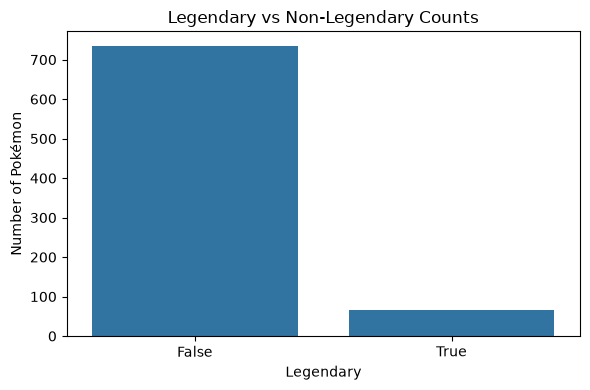

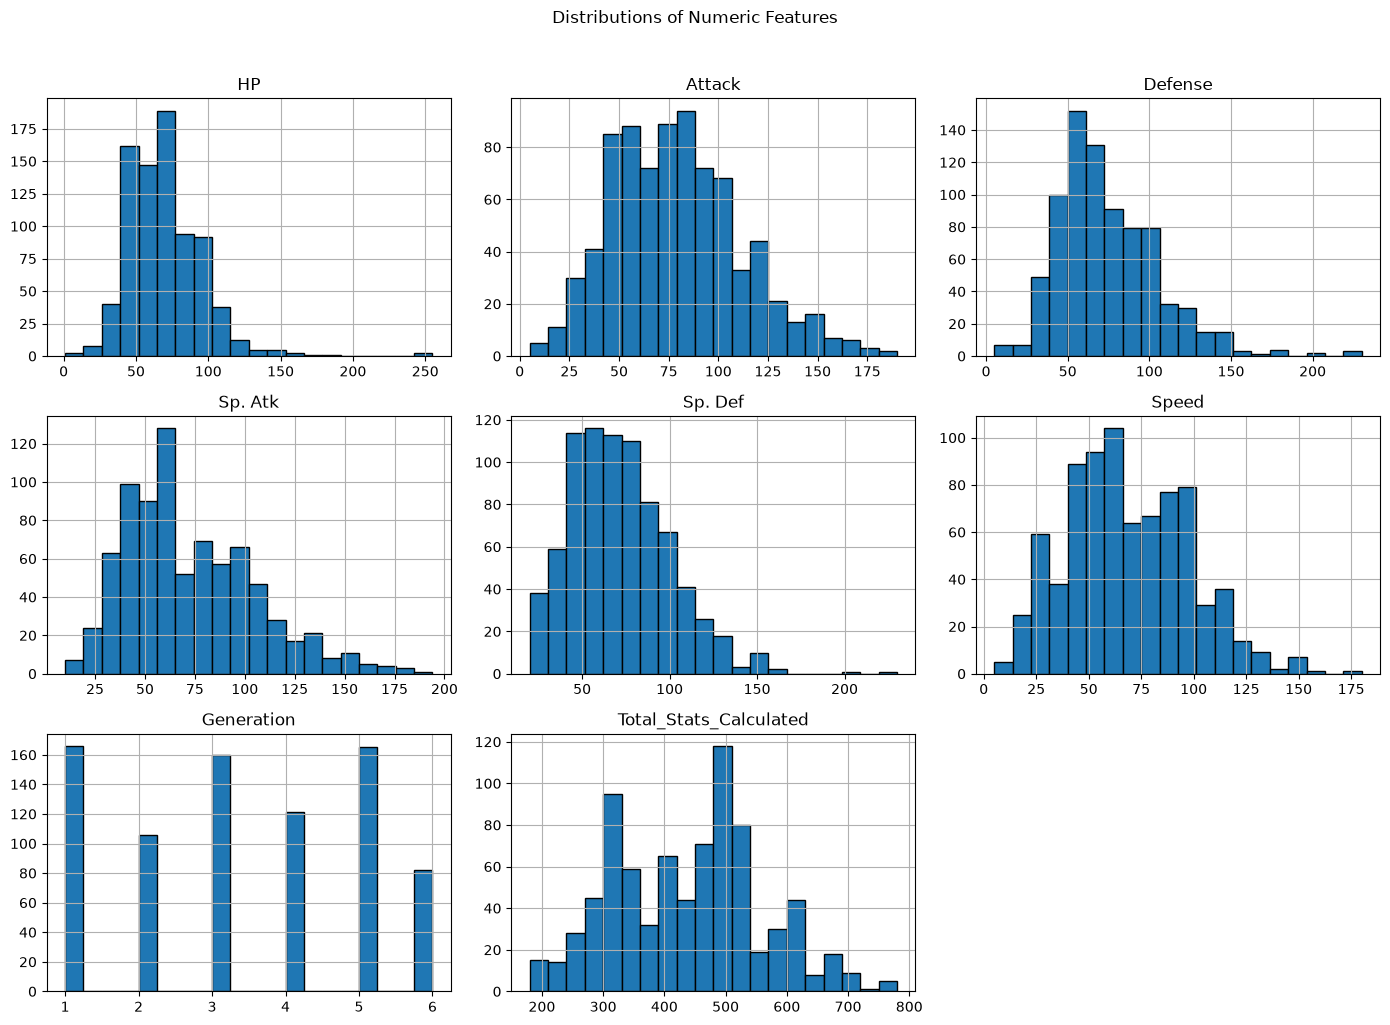

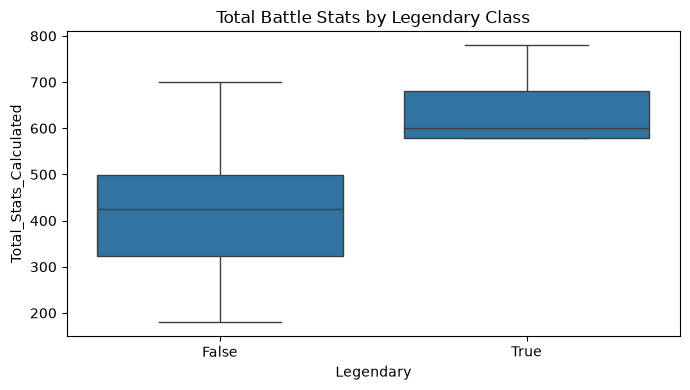

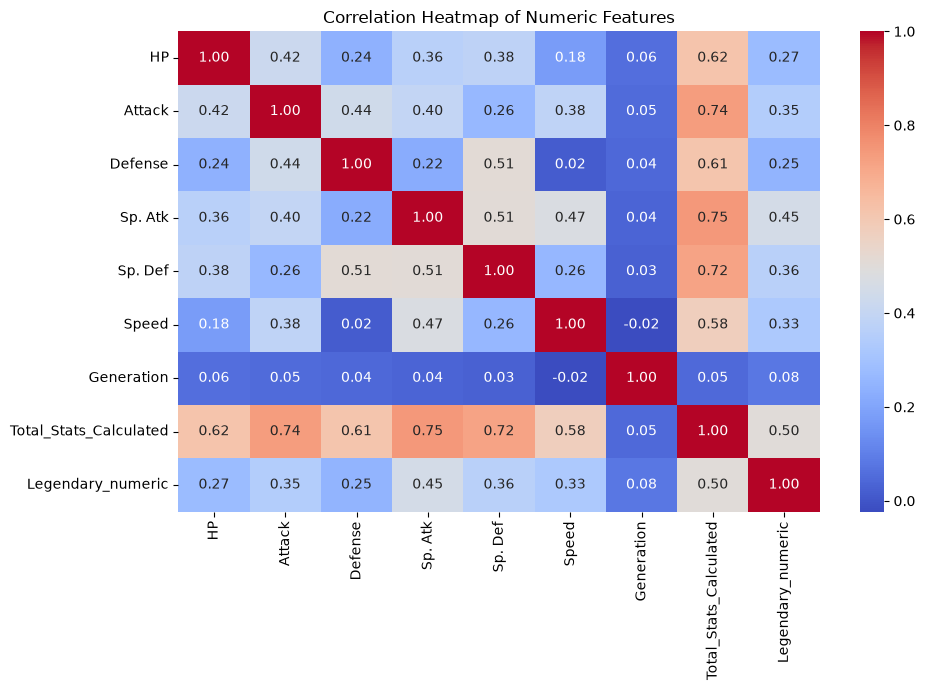

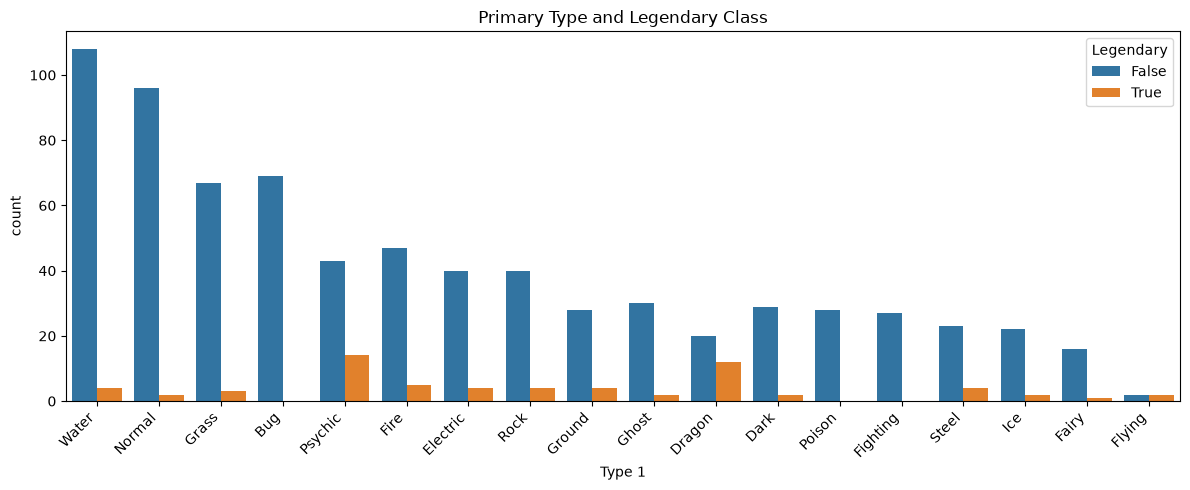

In [15]:
# 6
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="Legendary")
plt.title("Legendary vs Non-Legendary Counts")
plt.xlabel("Legendary")
plt.ylabel("Number of Pokémon")
plt.tight_layout()
plt.show()

numeric_for_hist = [c for c in df.select_dtypes(include=np.number).columns]
df[numeric_for_hist].hist(figsize=(14, 10), bins=20, edgecolor="black")
plt.suptitle("Distributions of Numeric Features", y=1.02)
plt.tight_layout()
plt.show()

if "Total_Stats_Calculated" in df.columns:
    plt.figure(figsize=(7, 4))
    sns.boxplot(data=df, x="Legendary", y="Total_Stats_Calculated")
    plt.title("Total Battle Stats by Legendary Class")
    plt.tight_layout()
    plt.show()

plt.figure(figsize=(10, 7))
corr_df = df.select_dtypes(include=np.number).copy()
corr_df["Legendary_numeric"] = df["Legendary"].astype(int)
sns.heatmap(corr_df.corr(), annot=True, cmap="coolwarm", fmt=".2f", square=False)
plt.title("Correlation Heatmap of Numeric Features")
plt.tight_layout()
plt.show()

if "Type 1" in df.columns:
    plt.figure(figsize=(12, 5))
    order = df["Type 1"].value_counts().index
    sns.countplot(data=df, x="Type 1", order=order, hue="Legendary")
    plt.title("Primary Type and Legendary Class")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()

In [17]:
# 7
y_text = df["Legendary"].astype(bool)
X_raw = df.drop(columns=["Legendary"]).copy()

# One-hot encode categorical columns. drop_first=True avoids a redundant reference category.
X = pd.get_dummies(X_raw, columns=X_raw.select_dtypes(include=["object", "category"]).columns,
                   drop_first=True, dtype=int)

le_y = LabelEncoder()
y = le_y.fit_transform(y_text)  # False -> 0, True -> 1 for Boolean labels

X_train_full, X_test_full, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print("Encoded feature matrix shape:", X.shape)
print("Training rows:", X_train_full.shape[0])
print("Testing rows:", X_test_full.shape[0])
print("Training class counts:", np.bincount(y_train))
print("Testing class counts:", np.bincount(y_test))

# Select up to 15 features using training data only.
k = min(15, X_train_full.shape[1])
selector = SelectKBest(score_func=f_classif, k=k)
X_train_selected = selector.fit_transform(X_train_full, y_train)
X_test_selected = selector.transform(X_test_full)
selected_features = X_train_full.columns[selector.get_support()].tolist()

print("\nSelected features:")
for feature in selected_features:
    print("-", feature)

# Fit the scaler only on training features.
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_selected)
X_test_scaled = scaler.transform(X_test_selected)

print("\nScaled training shape:", X_train_scaled.shape)
print("Scaled testing shape:", X_test_scaled.shape)

Encoded feature matrix shape: (800, 43)
Training rows: 640
Testing rows: 160
Training class counts: [588  52]
Testing class counts: [147  13]

Selected features:
- HP
- Attack
- Defense
- Sp. Atk
- Sp. Def
- Speed
- Total_Stats_Calculated
- Type 1_Dragon
- Type 1_Flying
- Type 1_Normal
- Type 1_Psychic
- Type 1_Water
- Type 2_Fire
- Type 2_Ice
- Type 2_Psychic

Scaled training shape: (640, 15)
Scaled testing shape: (160, 15)


C:\Users\arshi\AppData\Local\Temp\ipykernel_26404\2926735046.py:6: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  X = pd.get_dummies(X_raw, columns=X_raw.select_dtypes(include=["object", "category"]).columns,


,Setting,Threshold,Accuracy,Precision,Recall,F1,Specificity,AUC
0,"Baseline (scaled, default)",0.5,0.894,0.333,0.308,0.32,0.946,0.938


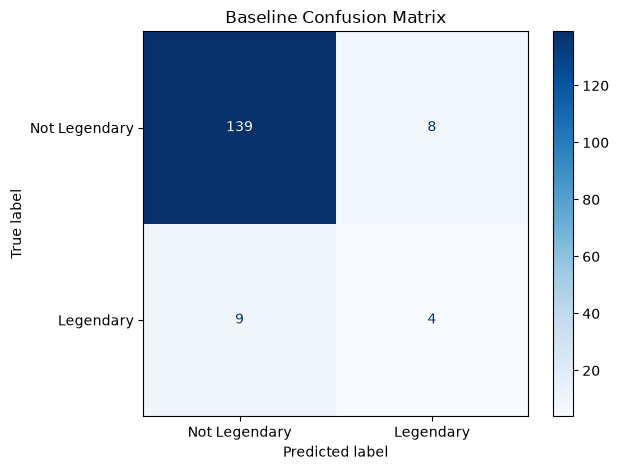

               precision    recall  f1-score   support

Not Legendary       0.94      0.95      0.94       147
    Legendary       0.33      0.31      0.32        13

     accuracy                           0.89       160
    macro avg       0.64      0.63      0.63       160
 weighted avg       0.89      0.89      0.89       160



In [19]:
# 8
results = []
fitted_models = {}

def evaluate(name, model, Xtr, Xte, ytr, yte, threshold=0.5, scaler_used=True):
    model.fit(Xtr, ytr)
    probabilities = model.predict_proba(Xte)[:, 1]
    predictions = (probabilities >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(yte, predictions, labels=[0, 1]).ravel()
    specificity = tn / (tn + fp) if (tn + fp) else 0.0

    row = {
        "Setting": name,
        "Threshold": threshold,
        "Accuracy": accuracy_score(yte, predictions),
        "Precision": precision_score(yte, predictions, zero_division=0),
        "Recall": recall_score(yte, predictions, zero_division=0),
        "F1": f1_score(yte, predictions, zero_division=0),
        "Specificity": specificity,
        "AUC": roc_auc_score(yte, probabilities)
    }
    results.append(row)
    fitted_models[name] = model
    return row, predictions, probabilities

baseline_model = LogisticRegression()
baseline_row, baseline_pred, baseline_prob = evaluate(
    "Baseline (scaled, default)", baseline_model,
    X_train_scaled, X_test_scaled, y_train, y_test
)
display(pd.DataFrame([baseline_row]).round(3))

ConfusionMatrixDisplay.from_predictions(
    y_test, baseline_pred, labels=[0, 1],
    display_labels=["Not Legendary", "Legendary"], cmap="Blues"
)
plt.title("Baseline Confusion Matrix")
plt.tight_layout()
plt.show()

print(classification_report(
    y_test, baseline_pred, labels=[0, 1],
    target_names=["Not Legendary", "Legendary"], zero_division=0
))

In [20]:
# 9
# Compare unscaled vs scaled, class weighting, and regularization.
# Every model here is Logistic Regression, as required.
settings = [
    ("Scaled, class_weight=None, C=1", X_train_scaled, X_test_scaled,
     {"class_weight": None, "C": 1.0}, 0.5),
    ("Scaled, balanced, C=1", X_train_scaled, X_test_scaled,
     {"class_weight": "balanced", "C": 1.0}, 0.5),
    ("Scaled, balanced, C=0.5", X_train_scaled, X_test_scaled,
     {"class_weight": "balanced", "C": 0.5}, 0.5),
    ("Scaled, balanced, C=2", X_train_scaled, X_test_scaled,
     {"class_weight": "balanced", "C": 2.0}, 0.5),
    ("Unscaled, balanced, C=1", X_train_selected, X_test_selected,
     {"class_weight": "balanced", "C": 1.0}, 0.5),
]

for name, Xtr, Xte, params, thr in settings:
    model = LogisticRegression(max_iter=1000, **params)
    evaluate(name, model, Xtr, Xte, y_train, y_test, threshold=thr)

# Compare decision thresholds using a separate balanced Logistic Regression model.
threshold_model = LogisticRegression(max_iter=1000, class_weight="balanced", C=1.0)
threshold_model.fit(X_train_scaled, y_train)
threshold_prob = threshold_model.predict_proba(X_test_scaled)[:, 1]

for thr in [0.3, 0.5, 0.7]:
    pred_thr = (threshold_prob >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred_thr, labels=[0, 1]).ravel()
    results.append({
        "Setting": f"Threshold comparison (balanced, threshold={thr})",
        "Threshold": thr,
        "Accuracy": accuracy_score(y_test, pred_thr),
        "Precision": precision_score(y_test, pred_thr, zero_division=0),
        "Recall": recall_score(y_test, pred_thr, zero_division=0),
        "F1": f1_score(y_test, pred_thr, zero_division=0),
        "Specificity": tn / (tn + fp) if tn + fp else 0.0,
        "AUC": roc_auc_score(y_test, threshold_prob)
    })

results_df = pd.DataFrame(results).drop_duplicates(subset=["Setting"], keep="last")
display(results_df.sort_values(["Recall", "F1"], ascending=False).round(3))

C:\Users\arshi\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


,Setting,Threshold,Accuracy,Precision,Recall,F1,Specificity,AUC
6,"Threshold comparison (balanced, threshold=0.3)",0.3,0.906,0.464,1.000,0.634,0.898,0.945
2,"Scaled, balanced, C=1",0.5,0.919,0.500,0.923,0.649,0.918,0.945
4,"Scaled, balanced, C=2",0.5,0.919,0.500,0.923,0.649,0.918,0.945
7,"Threshold comparison (balanced, threshold=0.5)",0.5,0.919,0.500,0.923,0.649,0.918,0.945
3,"Scaled, balanced, C=0.5",0.5,0.912,0.480,0.923,0.632,0.912,0.944
5,"Unscaled, balanced, C=1",0.5,0.912,0.480,0.923,0.632,0.912,0.952
8,"Threshold comparison (balanced, threshold=0.7)",0.7,0.888,0.368,0.538,0.438,0.918,0.945
0,"Baseline (scaled, default)",0.5,0.894,0.333,0.308,0.320,0.946,0.938
1,"Scaled, class_weight=None, C=1",0.5,0.894,0.333,0.308,0.320,0.946,0.938


In [21]:
# 10
coefficient_model = LogisticRegression(max_iter=1000, class_weight="balanced")
coefficient_model.fit(X_train_scaled, y_train)

print("Intercept:", coefficient_model.intercept_[0])
coef_table = pd.DataFrame({
    "Feature": selected_features,
    "Coefficient": coefficient_model.coef_[0]
})
coef_table["Absolute coefficient"] = coef_table["Coefficient"].abs()
display(coef_table.sort_values("Absolute coefficient", ascending=False).head(10).round(4))

Intercept: -7.604434686062058


,Feature,Coefficient,Absolute coefficient
5,Speed,1.7600,1.7600
6,Total_Stats_Calculated,1.7102,1.7102
0,HP,1.4735,1.4735
4,Sp. Def,1.4268,1.4268
9,Type 1_Normal,-1.1570,1.1570
3,Sp. Atk,1.1278,1.1278
2,Defense,0.9496,0.9496
10,Type 1_Psychic,0.5083,0.5083
11,Type 1_Water,-0.5024,0.5024
1,Attack,0.4221,0.4221


,Setting,Threshold,Accuracy,Precision,Recall,F1,Specificity,AUC
0,"Threshold comparison (balanced, threshold=0.3)",0.3,0.906,0.464,1.000,0.634,0.898,0.945
1,"Scaled, balanced, C=1",0.5,0.919,0.500,0.923,0.649,0.918,0.945
2,"Scaled, balanced, C=2",0.5,0.919,0.500,0.923,0.649,0.918,0.945
3,"Threshold comparison (balanced, threshold=0.5)",0.5,0.919,0.500,0.923,0.649,0.918,0.945
4,"Scaled, balanced, C=0.5",0.5,0.912,0.480,0.923,0.632,0.912,0.944
5,"Unscaled, balanced, C=1",0.5,0.912,0.480,0.923,0.632,0.912,0.952
6,"Threshold comparison (balanced, threshold=0.7)",0.7,0.888,0.368,0.538,0.438,0.918,0.945
7,"Baseline (scaled, default)",0.5,0.894,0.333,0.308,0.320,0.946,0.938
8,"Scaled, class_weight=None, C=1",0.5,0.894,0.333,0.308,0.320,0.946,0.938


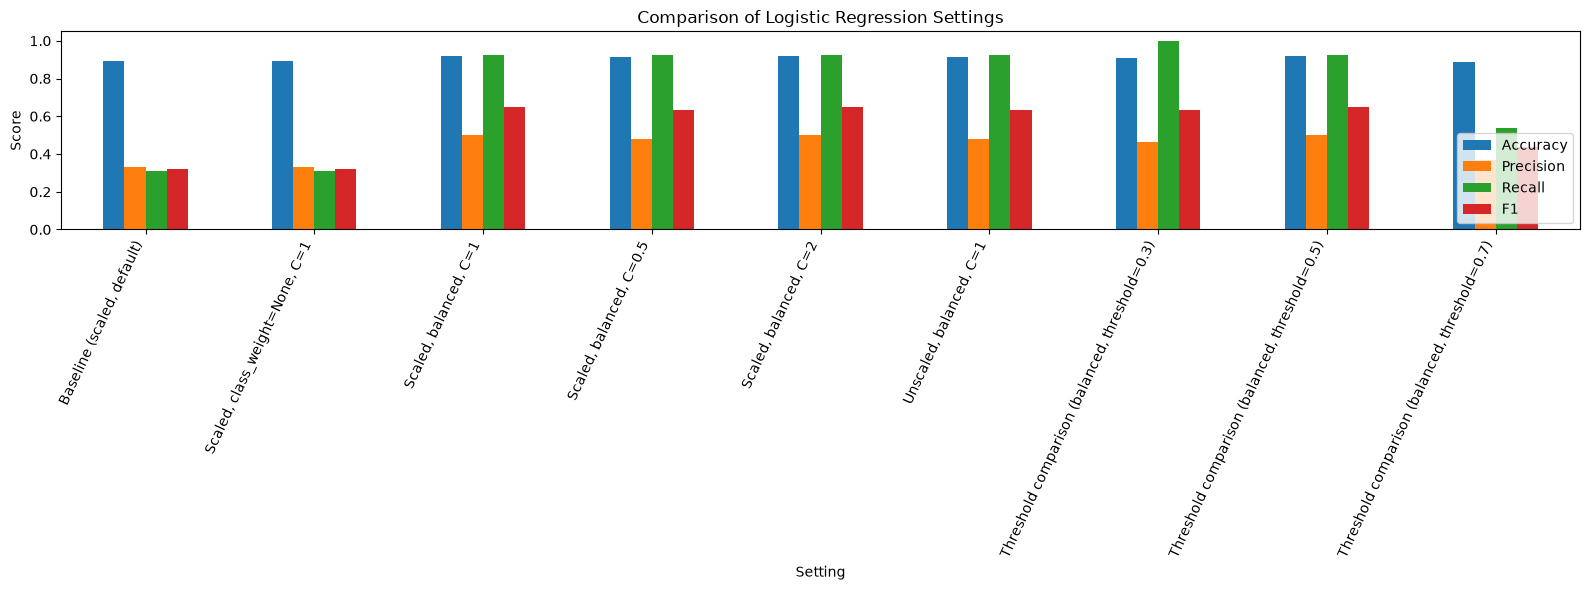

Top setting by Recall, then F1:


,Value
Setting,"Threshold comparison (balanced, threshold=0.3)"
Threshold,0.3
Accuracy,0.90625
Precision,0.464286
Recall,1.0
F1,0.634146
Specificity,0.897959
AUC,0.944532


Final metrics:


,Accuracy,Precision,Recall,F1,Specificity,AUC
0,0.906,0.464,1.0,0.634,0.898,0.945


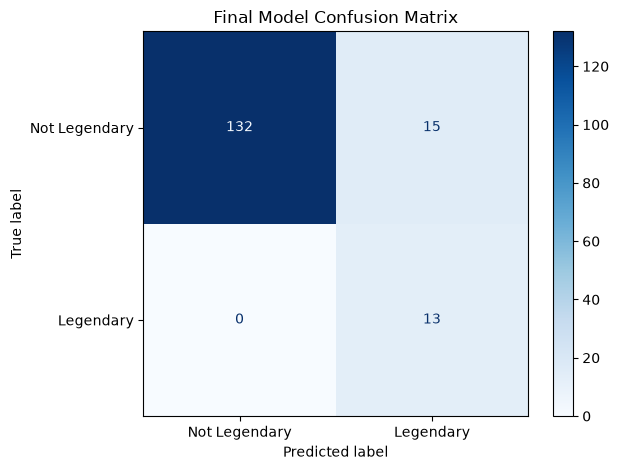

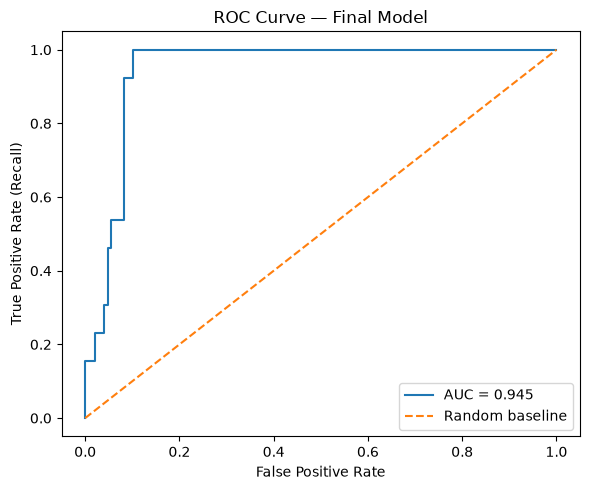

               precision    recall  f1-score   support

Not Legendary       1.00      0.90      0.95       147
    Legendary       0.46      1.00      0.63        13

     accuracy                           0.91       160
    macro avg       0.73      0.95      0.79       160
 weighted avg       0.96      0.91      0.92       160



In [22]:
# 11
comparison = results_df.sort_values(["Recall", "F1"], ascending=False).reset_index(drop=True)
display(comparison.round(3))

plot_df = results_df.set_index("Setting")[["Accuracy", "Precision", "Recall", "F1"]]
plot_df.plot(kind="bar", figsize=(16, 6))
plt.title("Comparison of Logistic Regression Settings")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=65, ha="right")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

# Choose by recall first and F1 as tie-breaker, as requested by the project brief.
best_row = results_df.sort_values(["Recall", "F1"], ascending=False).iloc[0]
print("Top setting by Recall, then F1:")
display(best_row.to_frame("Value"))

# Pick an operational threshold from the selected row.
# For threshold-comparison rows, reuse the balanced model and that threshold.
best_setting_name = best_row["Setting"]
best_threshold = float(best_row["Threshold"])

if best_setting_name.startswith("Threshold comparison"):
    final_model = LogisticRegression(max_iter=1000, class_weight="balanced", C=1.0)
    final_model.fit(X_train_scaled, y_train)
    final_X_test = X_test_scaled
    final_prob = final_model.predict_proba(final_X_test)[:, 1]
    final_pred = (final_prob >= best_threshold).astype(int)
elif best_setting_name.startswith("Unscaled"):
    final_model = LogisticRegression(max_iter=1000, class_weight="balanced", C=1.0)
    final_model.fit(X_train_selected, y_train)
    final_X_test = X_test_selected
    final_prob = final_model.predict_proba(final_X_test)[:, 1]
    final_pred = (final_prob >= best_threshold).astype(int)
else:
    # Recover the parameters from the chosen comparison row.
    chosen_params = {"max_iter": 1000}
    if "balanced" in best_setting_name:
        chosen_params["class_weight"] = "balanced"
    else:
        chosen_params["class_weight"] = None
    if "C=0.5" in best_setting_name:
        chosen_params["C"] = 0.5
    elif "C=2" in best_setting_name:
        chosen_params["C"] = 2.0
    else:
        chosen_params["C"] = 1.0
    final_model = LogisticRegression(**chosen_params)
    final_model.fit(X_train_scaled, y_train)
    final_X_test = X_test_scaled
    final_prob = final_model.predict_proba(final_X_test)[:, 1]
    final_pred = (final_prob >= best_threshold).astype(int)

tn, fp, fn, tp = confusion_matrix(y_test, final_pred, labels=[0, 1]).ravel()
final_metrics = {
    "Accuracy": accuracy_score(y_test, final_pred),
    "Precision": precision_score(y_test, final_pred, zero_division=0),
    "Recall": recall_score(y_test, final_pred, zero_division=0),
    "F1": f1_score(y_test, final_pred, zero_division=0),
    "Specificity": tn / (tn + fp) if tn + fp else 0.0,
    "AUC": roc_auc_score(y_test, final_prob)
}
print("Final metrics:")
display(pd.DataFrame([final_metrics]).round(3))

ConfusionMatrixDisplay.from_predictions(
    y_test, final_pred, labels=[0, 1],
    display_labels=["Not Legendary", "Legendary"], cmap="Blues"
)
plt.title("Final Model Confusion Matrix")
plt.tight_layout()
plt.show()

fpr, tpr, _ = roc_curve(y_test, final_prob)
plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, label=f"AUC = {roc_auc_score(y_test, final_prob):.3f}")
plt.plot([0, 1], [0, 1], linestyle="--", label="Random baseline")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate (Recall)")
plt.title("ROC Curve — Final Model")
plt.legend()
plt.tight_layout()
plt.show()

print(classification_report(
    y_test, final_pred, labels=[0, 1],
    target_names=["Not Legendary", "Legendary"], zero_division=0
))

In [23]:
# 12
# Start with three held-out encoded examples, then alter selected numeric source columns.
new_examples = X_test_full.iloc[:3].copy()

# Change numeric raw-stat features before feature selection, where available.
# These changes are modest and only illustrative.
for idx, factor in zip(new_examples.index, [0.90, 1.00, 1.10]):
    for col in ["HP", "Attack", "Defense", "Sp. Atk", "Sp. Def", "Speed"]:
        if col in new_examples.columns:
            new_examples.loc[idx, col] = max(1, new_examples.loc[idx, col] * factor)

new_selected = selector.transform(new_examples)
# The final model's feature space depends on whether the chosen configuration was scaled.
if best_setting_name.startswith("Unscaled"):
    new_model_input = new_selected
else:
    new_model_input = scaler.transform(new_selected)

new_probabilities = final_model.predict_proba(new_model_input)[:, 1]
new_predictions = (new_probabilities >= best_threshold).astype(int)

prediction_table = pd.DataFrame({
    "Example": ["Synthetic example 1", "Synthetic example 2", "Synthetic example 3"],
    "Predicted class": le_y.inverse_transform(new_predictions),
    "Probability of Legendary": new_probabilities.round(3)
})
display(prediction_table)

print("The predictions are model outputs, not guaranteed facts. Explain that the model uses learned patterns in the dataset.")

TypeError: Invalid value '67.5' for dtype 'int64'